# Evaluación Parcial 2 — Telco Customer Churn

## Caso A: Predicción de abandono de clientes

Una empresa de telecomunicaciones necesita comprender qué características presentan los clientes que abandonan el servicio y contar con herramientas que permitan anticipar ese comportamiento.

La variable objetivo es `Churn`:

- `Yes`: el cliente abandonó la empresa.
- `No`: el cliente permaneció en la empresa.

### Problema de negocio

El problema consiste en identificar clientes con riesgo de abandono para apoyar futuras estrategias de retención y, además, descubrir segmentos de clientes con características similares que permitan orientar acciones más específicas.

### Objetivo general

Desarrollar una solución de Machine Learning que permita analizar y predecir el abandono de clientes, comparando modelos supervisados e identificando segmentos relevantes mediante aprendizaje no supervisado.

### Objetivos específicos

- Comprender la estructura y calidad de los datos.
- Identificar patrones asociados al abandono mediante EDA.
- Preparar y transformar los datos para el modelamiento.
- Implementar y comparar dos modelos supervisados de clasificación.
- Evaluar su desempeño mediante métricas apropiadas.
- Aplicar K-Means para identificar segmentos de clientes.
- Visualizar los segmentos mediante PCA.
- Traducir los resultados al contexto de negocio.

### KPI principal

La **tasa global de abandono** se utiliza como línea base del problema. En el conjunto de datos, el 26,54% de los clientes presenta `Churn = Yes`.

Para evaluar los modelos se utilizarán Accuracy, Precision, Recall, F1-Score y ROC-AUC, prestando especial atención al Recall debido al interés de negocio en detectar clientes que realmente abandonan.


## 1. Carga de librerías y dataset

Se cargan las librerías necesarias y se importa el conjunto de datos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score
)

df = pd.read_csv("../data/Telco_Customer_Churn_Dataset.csv")
df.head()


ModuleNotFoundError: No module named 'matplotlib'

## 2. Revisión inicial del dataset

Se revisan las dimensiones, tipos de datos, valores nulos, duplicados y la distribución de `Churn`.

In [ ]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDuplicados:")
print(df.duplicated().sum())

print("\nDistribución de Churn:")
print(df["Churn"].value_counts())

print("\nPorcentaje de Churn:")
print(df["Churn"].value_counts(normalize=True) * 100)

Filas: 7043
Columnas: 21

Tipos de datos:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Valores nulos:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract  

### Interpretación de la revisión inicial

El conjunto de datos contiene **7.043 clientes y 21 variables**.

No se detectaron registros completamente duplicados ni valores nulos mediante la revisión inicial.

La variable objetivo `Churn` presenta la siguiente distribución:
- **73.46%** no abandonó.
- **26.54%** sí abandonó.

Existe desbalance entre las clases, por lo que más adelante no será suficiente evaluar los modelos únicamente mediante Accuracy; será necesario considerar otras métricas de clasificación.

## 3. Revisión de `TotalCharges`

`TotalCharges` aparece como tipo `object`, aunque conceptualmente corresponde a una variable numérica. Se revisa si existen espacios en blanco almacenados como texto.

In [ ]:
filas_vacias = df[df["TotalCharges"].str.strip() == ""]

print("Cantidad de TotalCharges vacíos:", len(filas_vacias))

filas_vacias[
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

Cantidad de TotalCharges vacíos: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### Interpretación

Se identificaron **11 registros** con `TotalCharges` vacío.

Estos valores no fueron detectados inicialmente como nulos porque estaban almacenados como espacios en blanco.

Además, los 11 casos corresponden a clientes con `tenure = 0`, es decir, sin antigüedad acumulada.

## 4. Tratamiento de `TotalCharges`

Se convierte la columna a formato numérico. Los espacios pasan a `NaN` y luego se reemplazan por 0 porque corresponden a clientes con `tenure = 0`.

In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Nulos después de convertir:", df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Tipo final:", df["TotalCharges"].dtype)
print("Nulos finales:", df["TotalCharges"].isnull().sum())

Nulos después de convertir: 11
Tipo final: float64
Nulos finales: 0


### Decisión de preparación

`TotalCharges` quedó como variable numérica (`float64`) y sin valores faltantes.

Los 11 valores vacíos se reemplazaron por 0 porque pertenecían a clientes con `tenure = 0`, lo que es coherente con que aún no tengan cargos totales acumulados registrados.

## 5. EDA de variables numéricas

Se comparan `tenure`, `MonthlyCharges` y `TotalCharges` según `Churn` para identificar diferencias entre quienes permanecen y quienes abandonan.

In [ ]:
promedios_churn = (
    df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]]
    .mean()
    .round(2)
)

promedios_churn

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


### Interpretación

Los clientes que **no abandonan** tienen una antigüedad promedio de aproximadamente **37.57 meses**, mientras que quienes **sí abandonan** tienen aproximadamente **17.98 meses**.

Los clientes que abandonan presentan cargos mensuales promedio más altos (**74.44**) que quienes permanecen (**61.27**).

`TotalCharges` es menor entre quienes abandonan, lo que es coherente con su menor antigüedad.

Estos resultados muestran asociaciones, no causalidad.

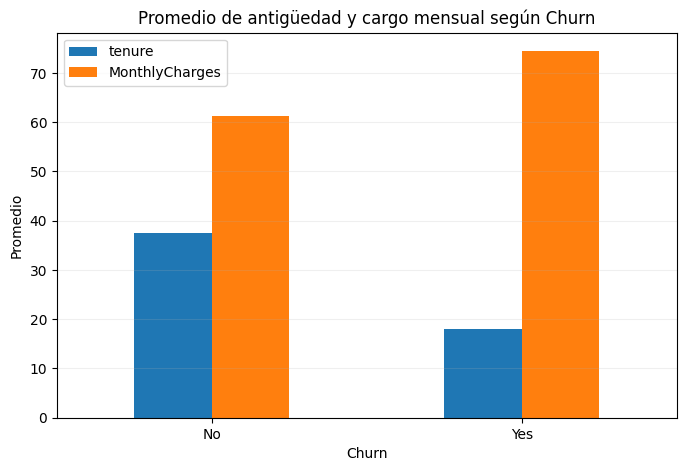

In [ ]:
promedios = df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean()

promedios.plot(kind="bar", figsize=(8, 5))
plt.title("Promedio de antigüedad y cargo mensual según Churn")
plt.ylabel("Promedio")
plt.xlabel("Churn")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.2)
plt.show()

## 6. Relación entre tipo de contrato y abandono

Se analiza la tasa de abandono según el tipo de contrato.

In [ ]:
tabla_contrato = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

display(tabla_contrato)

porcentaje_contrato = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_contrato.round(2)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


### Interpretación

La tasa de abandono cambia considerablemente según el contrato:

- `Month-to-month`: **42.71%**
- `One year`: **11.27%**
- `Two year`: **2.83%**

Los contratos mes a mes presentan una proporción de abandono mucho mayor.

Desde el punto de vista del negocio, este segmento podría requerir mayor atención en estrategias de retención.

La relación observada es una asociación y no demuestra causalidad.

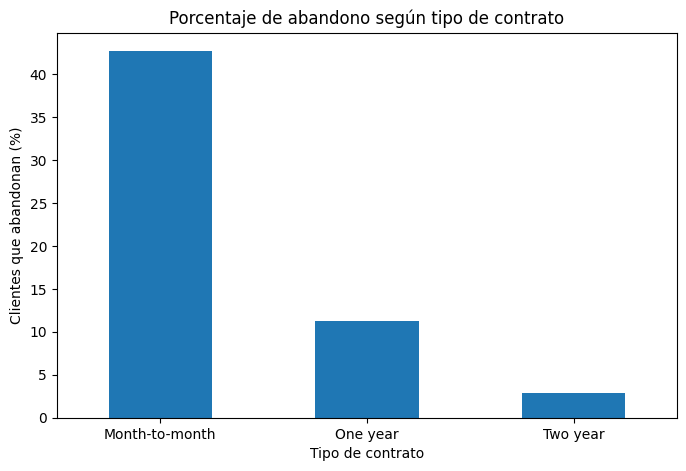

In [ ]:
tasa_churn_contrato = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

tasa_churn_contrato.plot(kind="bar", figsize=(8, 5))
plt.title("Porcentaje de abandono según tipo de contrato")
plt.ylabel("Clientes que abandonan (%)")
plt.xlabel("Tipo de contrato")
plt.xticks(rotation=0)
plt.show()

## 7. Relación entre servicio de Internet y abandono

Se analiza la tasa de abandono según el tipo de servicio de Internet.

In [ ]:
porcentaje_internet = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_internet.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


### Interpretación

Los clientes con **fibra óptica** presentan una tasa de abandono de aproximadamente **41.89%**, superior a DSL (**18.96%**) y a quienes no poseen servicio de Internet (**7.4%**).

Esto indica que el tipo de servicio de Internet presenta diferencias relevantes respecto al abandono.

El análisis muestra una asociación y no permite afirmar causalidad.

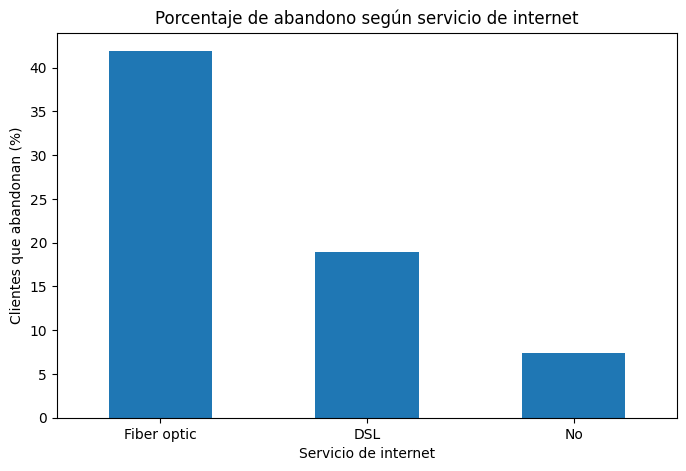

In [ ]:
tasa_churn_internet = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

tasa_churn_internet.plot(kind="bar", figsize=(8, 5))
plt.title("Porcentaje de abandono según servicio de internet")
plt.ylabel("Clientes que abandonan (%)")
plt.xlabel("Servicio de internet")
plt.xticks(rotation=0)
plt.show()

## 8. Relación entre método de pago y abandono

Se analiza la tasa de abandono según el método de pago utilizado por los clientes.

El objetivo es identificar si existen diferencias relevantes en el comportamiento de abandono entre los distintos métodos de pago.

In [ ]:
porcentaje_pago = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_pago.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


### Interpretación

Se observan diferencias importantes en la tasa de abandono según el método de pago.

Los clientes que utilizan `Electronic check` presentan la mayor tasa de abandono, con aproximadamente un **45,29%**.

En comparación:

- `Mailed check`: 19,11% de abandono.
- `Bank transfer (automatic)`: 16,71%.
- `Credit card (automatic)`: 15,24%.

Esto muestra que, dentro del conjunto de datos, el uso de `Electronic check` está asociado a una mayor proporción de abandono.

Desde una perspectiva de negocio, este grupo de clientes podría ser relevante para profundizar el análisis de retención.

Esta relación corresponde a una asociación observada en los datos y no permite afirmar que el método de pago sea la causa directa del abandono.

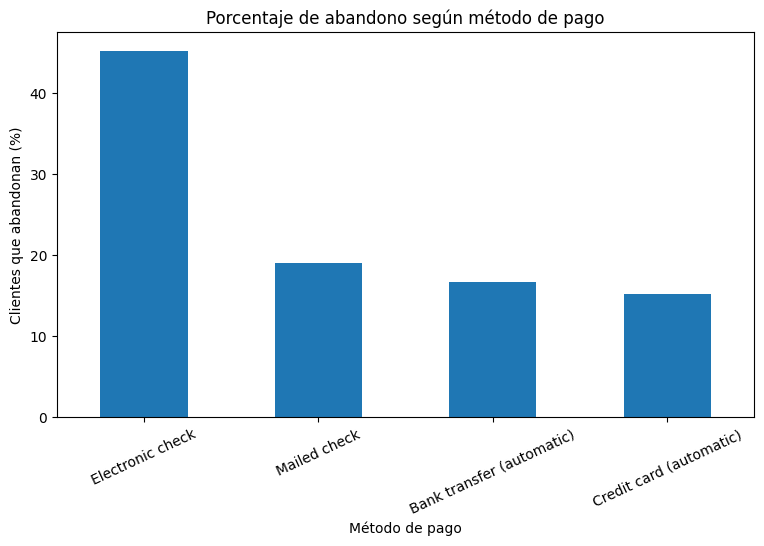

In [ ]:
tasa_churn_pago = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

tasa_churn_pago.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Porcentaje de abandono según método de pago")
plt.ylabel("Clientes que abandonan (%)")
plt.xlabel("Método de pago")
plt.xticks(rotation=25)
plt.show()

## 9. Relación entre soporte técnico, seguridad online y abandono

Se analiza la tasa de abandono según la contratación de los servicios `TechSupport` y `OnlineSecurity`.

El objetivo es identificar si existen diferencias relevantes entre clientes que cuentan con estos servicios y aquellos que no los tienen.

In [ ]:
porcentaje_soporte = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_soporte.round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


### Interpretación de `TechSupport`

Los clientes que no cuentan con soporte técnico presentan una tasa de abandono aproximada de **41,64%**.

En cambio, entre quienes sí poseen soporte técnico, la tasa de abandono disminuye a aproximadamente **15,17%**.

Los clientes que no poseen servicio de Internet presentan una tasa de abandono aún menor, cercana al **7,40%**.

Estos resultados muestran una asociación entre la disponibilidad de soporte técnico y el abandono. Sin embargo, no permiten afirmar que la ausencia de soporte técnico sea la causa directa del churn.

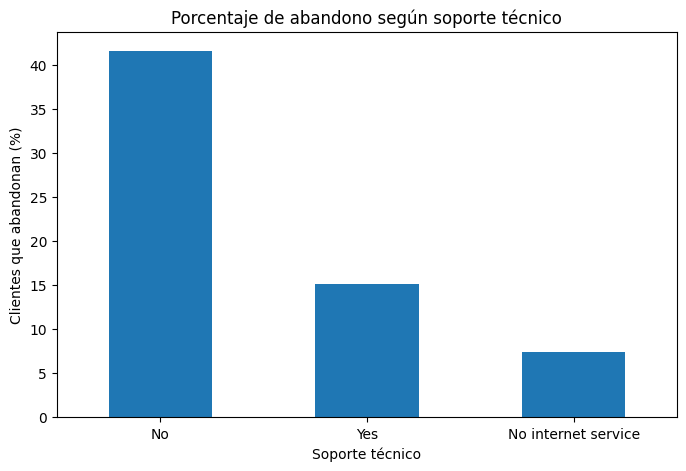

In [ ]:
tasa_churn_soporte = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

tasa_churn_soporte.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Porcentaje de abandono según soporte técnico")
plt.ylabel("Clientes que abandonan (%)")
plt.xlabel("Soporte técnico")
plt.xticks(rotation=0)
plt.show()

### Análisis de `OnlineSecurity`

También se analiza la tasa de abandono según la contratación del servicio de seguridad online.

In [ ]:
porcentaje_seguridad = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_seguridad.round(2)

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


### Interpretación de `OnlineSecurity`

Los clientes que no cuentan con seguridad online presentan una tasa de abandono aproximada de **41,77%**.

Entre quienes sí poseen este servicio, la tasa disminuye a aproximadamente **14,61%**.

Al igual que con `TechSupport`, se observa que los clientes que no poseen estos servicios presentan una mayor proporción de abandono.

Esto sugiere que la contratación de servicios adicionales podría estar asociada con una mayor permanencia del cliente, aunque el análisis no permite establecer causalidad.

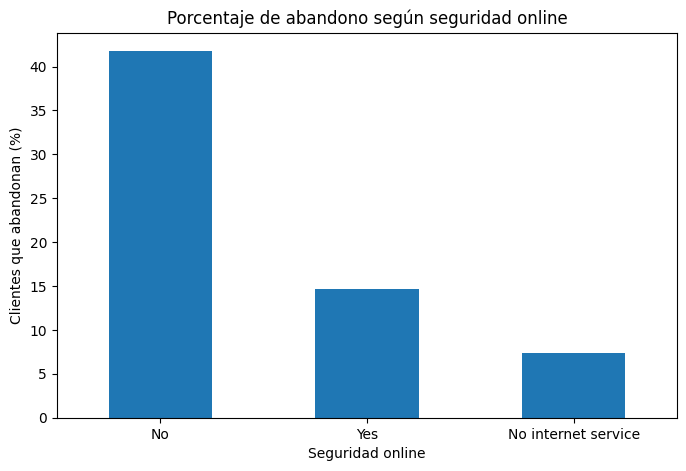

In [ ]:
tasa_churn_seguridad = (
    df.groupby("OnlineSecurity")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

tasa_churn_seguridad.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Porcentaje de abandono según seguridad online")
plt.ylabel("Clientes que abandonan (%)")
plt.xlabel("Seguridad online")
plt.xticks(rotation=0)
plt.show()

## 10. Relación entre características del cliente y abandono

Para complementar el análisis exploratorio, se revisan las variables `SeniorCitizen`, `Partner` y `Dependents`.

El objetivo es identificar si existen diferencias en la tasa de abandono según algunas características personales y familiares de los clientes.

In [ ]:
porcentaje_senior = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_senior.round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


### Interpretación de `SeniorCitizen`

Los clientes identificados como adultos mayores (`SeniorCitizen = 1`) presentan una tasa de abandono aproximada de **41,68%**.

En cambio, entre los clientes que no pertenecen a este grupo (`SeniorCitizen = 0`), la tasa de abandono es de aproximadamente **23,61%**.

Por lo tanto, se observa una diferencia relevante en la proporción de abandono entre ambos grupos.

Sin embargo, este resultado corresponde a una asociación observada en los datos y no implica que la edad sea la causa directa del abandono.

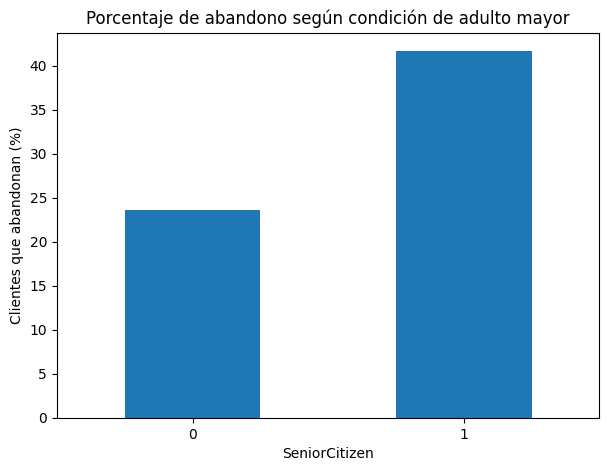

In [ ]:
tasa_churn_senior = (
    df.groupby("SeniorCitizen")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

tasa_churn_senior.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Porcentaje de abandono según condición de adulto mayor")
plt.ylabel("Clientes que abandonan (%)")
plt.xlabel("SeniorCitizen")
plt.xticks(rotation=0)
plt.show()

### Análisis de `Partner`

Se analiza la tasa de abandono según si el cliente tiene o no pareja.

In [ ]:
porcentaje_partner = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_partner.round(2)

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


### Interpretación de `Partner`

Los clientes que no tienen pareja presentan una tasa de abandono aproximada de **32,96%**.

En cambio, quienes sí tienen pareja presentan una tasa de abandono cercana al **19,66%**.

Esto muestra que existe una diferencia en el comportamiento de abandono según esta variable, aunque no se puede establecer una relación causal.

### Análisis de `Dependents`

Finalmente, se analiza la tasa de abandono según si el cliente tiene o no personas dependientes.

In [ ]:
porcentaje_dependientes = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

porcentaje_dependientes.round(2)

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


### Interpretación de `Dependents`

Los clientes sin dependientes presentan una tasa de abandono aproximada de **31,28%**.

Por otro lado, los clientes con dependientes presentan una tasa de abandono cercana al **15,45%**.

Esto indica que la tasa de abandono es mayor entre los clientes sin dependientes.

Al igual que en los análisis anteriores, esta diferencia representa una asociación observada en los datos y no una relación causal.

## 11. Principales hallazgos del análisis exploratorio

El análisis exploratorio permitió identificar varios patrones asociados al abandono de clientes.

Los clientes con mayor tasa de abandono tienden a presentar las siguientes características:

- Contrato mes a mes.
- Servicio de Internet mediante fibra óptica.
- Método de pago `Electronic check`.
- Ausencia de soporte técnico.
- Ausencia de seguridad online.
- Menor antigüedad en la empresa.
- Cargos mensuales promedio más altos.

También se observaron diferencias en variables como `SeniorCitizen`, `Partner` y `Dependents`.

Estos resultados permiten comprender mejor el comportamiento de los clientes antes de construir los modelos de Machine Learning.

Es importante señalar que los patrones identificados representan asociaciones observadas en los datos y no necesariamente relaciones causales.

## 12. Preparación de los datos para Machine Learning

Antes de entrenar los modelos, se prepara el conjunto de datos para que las variables puedan ser utilizadas por los algoritmos.

En esta etapa se realizarán las siguientes acciones:

- Eliminar `customerID`, ya que corresponde a un identificador y no representa una característica del comportamiento del cliente.
- Separar la variable objetivo `Churn`.
- Convertir `Churn` a valores numéricos.
- Transformar las variables categóricas a formato numérico.
- Separar los datos en conjuntos de entrenamiento y prueba.

In [ ]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

print("\nPorcentaje:")
print(y.value_counts(normalize=True) * 100)

Dimensiones de X: (7043, 19)
Dimensiones de y: (7043,)

Distribución de la variable objetivo:
Churn
0    5174
1    1869
Name: count, dtype: int64

Porcentaje:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


### Separación de variables

Se eliminó `customerID` porque funciona únicamente como identificador de cada cliente y no representa una característica útil para explicar su comportamiento.

La variable objetivo `Churn` se transformó a formato numérico:

- `0`: el cliente no abandona.
- `1`: el cliente abandona.

La distribución de la variable objetivo se mantiene igual que en el análisis inicial.

## 13. Conversión de variables categóricas

El conjunto de datos contiene varias variables categóricas representadas mediante texto.

Para poder utilizarlas en los modelos de Machine Learning, se transforman a variables numéricas mediante codificación de variables categóricas.

In [ ]:
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Nuevas dimensiones de X:", X.shape)

X.head()

Nuevas dimensiones de X: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


### Interpretación de la transformación

Las variables categóricas fueron convertidas a variables numéricas mediante `pd.get_dummies()`.

Se utilizó `drop_first=True` para evitar generar columnas redundantes entre las distintas categorías.

Después de esta transformación, todas las variables utilizadas por los modelos se encuentran en formato numérico.

## 14. División en entrenamiento y prueba

El conjunto de datos se divide en dos partes:

- 80% para entrenamiento.
- 20% para prueba.

El conjunto de entrenamiento se utilizará para que los modelos aprendan los patrones presentes en los datos.

El conjunto de prueba se utilizará posteriormente para evaluar el desempeño de los modelos con datos que no fueron utilizados durante el entrenamiento.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())

X_train: (5634, 30)
X_test: (1409, 30)

y_train:
Churn
0    4139
1    1495
Name: count, dtype: int64

y_test:
Churn
0    1035
1     374
Name: count, dtype: int64


### Interpretación de la división

Los datos se dividieron utilizando un 80% para entrenamiento y un 20% para prueba.

Se utilizó `stratify=y` para mantener una proporción similar de clientes que abandonan y no abandonan en ambos conjuntos.

De esta forma, tanto el entrenamiento como la evaluación mantienen una distribución representativa de la variable objetivo.

### Línea base de Accuracy

Como la clase mayoritaria corresponde a clientes que no abandonan, se calcula una línea base simple: qué Accuracy se obtendría si se predijera siempre la clase mayoritaria.

Esta referencia permite contextualizar el Accuracy de los modelos y evitar interpretarlo de forma aislada.

In [ ]:
accuracy_base = y_test.value_counts(normalize=True).max()

print(
    "Accuracy de la línea base (predecir siempre la clase mayoritaria):",
    round(accuracy_base, 4)
)

Accuracy de la línea base (predecir siempre la clase mayoritaria): 0.7346


La línea base es aproximadamente **73,46%**. Por lo tanto, un modelo útil debería superar esta referencia y, además, mostrar capacidad real para detectar a los clientes que abandonan mediante métricas como Recall y F1-Score.

## 15. Escalamiento de datos para Regresión Logística

Para entrenar la Regresión Logística se genera una versión escalada de las variables mediante `StandardScaler`.

El escalador se ajusta únicamente con el conjunto de entrenamiento y posteriormente se aplica al conjunto de prueba.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Entrenamiento escalado:", X_train_scaled.shape)
print("Prueba escalada:", X_test_scaled.shape)

Entrenamiento escalado: (5634, 30)
Prueba escalada: (1409, 30)


### Interpretación del escalamiento

Se aplicó `StandardScaler` al conjunto que será utilizado por la Regresión Logística.

El escalador fue ajustado únicamente con los datos de entrenamiento y luego aplicado a los datos de prueba.

De esta forma, el conjunto de prueba permanece separado del proceso de aprendizaje.

## 16. Modelo 1: Regresión Logística

El primer modelo supervisado utilizado es la Regresión Logística.

Este algoritmo se utiliza para problemas de clasificación y, en este caso, busca predecir si un cliente abandonará o no la empresa.

La variable objetivo está representada de la siguiente manera:

- `0`: el cliente no abandona.
- `1`: el cliente abandona.

El modelo será entrenado utilizando los datos previamente escalados.

In [ ]:
modelo_logistico = LogisticRegression()

modelo_logistico.fit(
    X_train_scaled,
    y_train
)

print("Modelo de Regresión Logística entrenado correctamente.")

Modelo de Regresión Logística entrenado correctamente.


## 17. Predicciones de la Regresión Logística

Una vez entrenado el modelo, se realizan predicciones sobre el conjunto de prueba.

También se obtienen las probabilidades estimadas de pertenecer a la clase positiva (`Churn = 1`), necesarias para calcular ROC-AUC.

In [ ]:
y_pred_logistico = modelo_logistico.predict(
    X_test_scaled
)

y_prob_logistico = modelo_logistico.predict_proba(
    X_test_scaled
)[:, 1]

print("Cantidad de predicciones:", len(y_pred_logistico))

Cantidad de predicciones: 1409


## 18. Evaluación de la Regresión Logística

El desempeño del modelo se evalúa mediante distintas métricas de clasificación.

Se utilizan:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** proporción de predicciones positivas que realmente eran positivas.
- **Recall:** proporción de clientes que realmente abandonaron y fueron detectados por el modelo.
- **F1-Score:** equilibrio entre Precision y Recall.
- **ROC-AUC:** capacidad del modelo para distinguir entre ambas clases.

Debido al desbalance observado en la variable `Churn`, las métricas se analizarán en conjunto y no únicamente mediante Accuracy.

In [ ]:
accuracy_logistico = accuracy_score(
    y_test,
    y_pred_logistico
)

precision_logistico = precision_score(
    y_test,
    y_pred_logistico
)

recall_logistico = recall_score(
    y_test,
    y_pred_logistico
)

f1_logistico = f1_score(
    y_test,
    y_pred_logistico
)

auc_logistico = roc_auc_score(
    y_test,
    y_prob_logistico
)

print("Accuracy:", round(accuracy_logistico, 4))
print("Precision:", round(precision_logistico, 4))
print("Recall:", round(recall_logistico, 4))
print("F1-Score:", round(f1_logistico, 4))
print("ROC-AUC:", round(auc_logistico, 4))

Accuracy: 0.807
Precision: 0.6584
Recall: 0.5668
F1-Score: 0.6092
ROC-AUC: 0.8418


### Interpretación de la Regresión Logística

La Regresión Logística obtuvo los siguientes resultados:

- **Accuracy: 80,70%**
- **Precision: 65,84%**
- **Recall: 56,68%**
- **F1-Score: 60,92%**
- **ROC-AUC: 84,18%**

El Accuracy indica que el modelo clasifica correctamente aproximadamente al 80,7% de los clientes en general.

La Precision de 65,84% indica que, cuando el modelo predice que un cliente abandonará, aproximadamente el 65,84% de esas predicciones son correctas.

El Recall de 56,68% indica que el modelo logra detectar aproximadamente al 56,68% de los clientes que realmente abandonan. Esto también significa que cerca del 43,32% de los abandonos reales no están siendo detectados.

El F1-Score de 60,92% muestra el equilibrio alcanzado entre Precision y Recall.

Finalmente, el ROC-AUC de 84,18% indica que el modelo presenta una buena capacidad para distinguir entre clientes que abandonan y clientes que permanecen.

Debido a que el objetivo del negocio es identificar clientes con riesgo de abandono, el Recall resulta especialmente relevante. Aunque el modelo presenta un buen desempeño general y una buena capacidad de discriminación, todavía deja sin detectar una proporción importante de clientes que realmente abandonan.

Por esta razón, aún no se puede decidir si este es el modelo más adecuado. Será necesario compararlo con el segundo modelo supervisado antes de realizar una recomendación final.

## 19. Matriz de confusión de la Regresión Logística

La matriz de confusión permite observar con mayor detalle los aciertos y errores del modelo.

En este problema resulta especialmente importante revisar los falsos negativos, ya que corresponden a clientes que realmente abandonaron, pero que el modelo clasificó como clientes que permanecerían.

[[925 110]
 [162 212]]


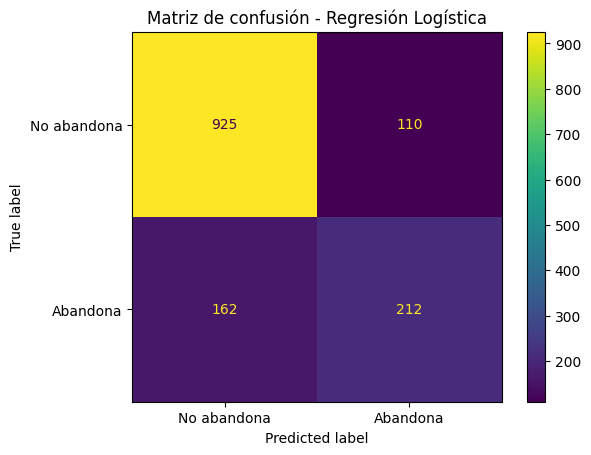

In [ ]:
matriz_logistico = confusion_matrix(
    y_test,
    y_pred_logistico
)

print(matriz_logistico)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistico,
    display_labels=["No abandona", "Abandona"]
).plot()

plt.title("Matriz de confusión - Regresión Logística")
plt.show()

### Interpretación de la matriz de confusión

La matriz de confusión permite observar con mayor detalle el comportamiento de la Regresión Logística.

El modelo obtuvo:

- **925 verdaderos negativos:** clientes que no abandonaron y fueron correctamente clasificados.
- **110 falsos positivos:** clientes que no abandonaron, pero fueron clasificados como posibles abandonos.
- **162 falsos negativos:** clientes que realmente abandonaron, pero el modelo no logró detectarlos.
- **212 verdaderos positivos:** clientes que abandonaron y fueron correctamente identificados.

En el conjunto de prueba existían **374 clientes que realmente abandonaron**. El modelo logró detectar correctamente a **212**, mientras que **162 abandonos no fueron identificados**.

Este resultado coincide con el Recall de **56,68%**, ya que el modelo detecta algo más de la mitad de los abandonos reales.

Desde el punto de vista del negocio, los falsos negativos son especialmente relevantes, porque representan clientes con riesgo de abandono que podrían no recibir una acción preventiva de retención.

Por lo tanto, aunque la Regresión Logística presenta un buen desempeño general, todavía existe una cantidad importante de clientes que abandonan y no son detectados.

## 20. Modelo 2: Árbol de Decisión

El segundo modelo supervisado utilizado es un Árbol de Decisión.

A diferencia de la Regresión Logística, este modelo construye reglas de decisión a partir de las características de los clientes.

Para evitar utilizar arbitrariamente la configuración por defecto, se optimiza el hiperparámetro `max_depth` mediante `GridSearchCV`, utilizando validación cruzada y F1-Score como criterio de selección.

El objetivo sigue siendo predecir si un cliente abandonará o no la empresa.

In [ ]:
parametros_arbol = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None]
}

busqueda_arbol = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parametros_arbol,
    scoring="f1",
    cv=5
)

busqueda_arbol.fit(
    X_train,
    y_train
)

modelo_arbol = busqueda_arbol.best_estimator_

print("Mejor max_depth:", busqueda_arbol.best_params_["max_depth"])
print("Mejor F1 promedio en validación cruzada:",
      round(busqueda_arbol.best_score_, 4))

Mejor max_depth: 6
Mejor F1 promedio en validación cruzada: 0.5493


## 21. Predicciones del Árbol de Decisión

Una vez entrenado el modelo, se realizan predicciones sobre el mismo conjunto de prueba utilizado anteriormente.

También se obtienen las probabilidades estimadas para la clase positiva (`Churn = 1`) con el objetivo de calcular ROC-AUC.

In [ ]:
y_pred_arbol = modelo_arbol.predict(
    X_test
)

y_prob_arbol = modelo_arbol.predict_proba(
    X_test
)[:, 1]

print("Cantidad de predicciones:", len(y_pred_arbol))

Cantidad de predicciones: 1409


## 22. Evaluación del Árbol de Decisión

El Árbol de Decisión se evalúa utilizando las mismas métricas aplicadas a la Regresión Logística:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.

Utilizar las mismas métricas y el mismo conjunto de prueba permite comparar ambos modelos bajo las mismas condiciones.

In [ ]:
accuracy_arbol = accuracy_score(
    y_test,
    y_pred_arbol
)

precision_arbol = precision_score(
    y_test,
    y_pred_arbol
)

recall_arbol = recall_score(
    y_test,
    y_pred_arbol
)

f1_arbol = f1_score(
    y_test,
    y_pred_arbol
)

auc_arbol = roc_auc_score(
    y_test,
    y_prob_arbol
)

print("Accuracy:", round(accuracy_arbol, 4))
print("Precision:", round(precision_arbol, 4))
print("Recall:", round(recall_arbol, 4))
print("F1-Score:", round(f1_arbol, 4))
print("ROC-AUC:", round(auc_arbol, 4))

Accuracy: 0.8006
Precision: 0.6667
Recall: 0.4973
F1-Score: 0.5697
ROC-AUC: 0.8219


### Interpretación del Árbol de Decisión

Después de optimizar `max_depth` mediante GridSearchCV, el mejor Árbol de Decisión obtuvo:

- **Accuracy: 80,06%**
- **Precision: 66,67%**
- **Recall: 49,73%**
- **F1-Score: 56,97%**
- **ROC-AUC: 82,19%**

El Accuracy indica que el modelo clasifica correctamente aproximadamente al 80,06% de los clientes.

La Precision de 66,67% indica que, cuando el modelo predice abandono, aproximadamente dos de cada tres predicciones positivas son correctas.

El Recall de 49,73% muestra que el modelo detecta aproximadamente a la mitad de los clientes que realmente abandonan, por lo que todavía deja sin identificar una cantidad importante de casos positivos.

El ROC-AUC de 82,19% indica una capacidad razonable para distinguir entre clientes que abandonan y clientes que permanecen.

Debido a que el objetivo del negocio es detectar clientes con riesgo de abandono, el Recall sigue siendo una métrica especialmente relevante.

## 23. Matriz de confusión del Árbol de Decisión

La matriz de confusión permite observar con mayor detalle los aciertos y errores cometidos por el Árbol de Decisión.

En este problema resulta especialmente importante revisar los falsos negativos, ya que corresponden a clientes que realmente abandonaron, pero que el modelo clasificó como clientes que permanecerían.

[[942  93]
 [188 186]]


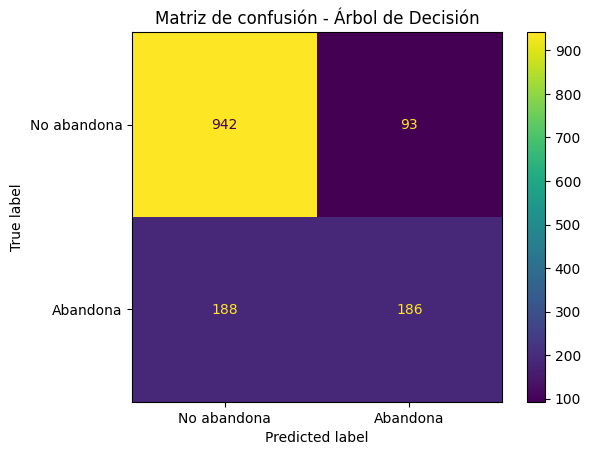

In [ ]:
matriz_arbol = confusion_matrix(
    y_test,
    y_pred_arbol
)

print(matriz_arbol)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_arbol,
    display_labels=["No abandona", "Abandona"]
).plot()

plt.title("Matriz de confusión - Árbol de Decisión")
plt.show()

### Interpretación de la matriz de confusión

La matriz de confusión del Árbol de Decisión optimizado muestra:

- **942 verdaderos negativos:** clientes que no abandonaron y fueron correctamente clasificados.
- **93 falsos positivos:** clientes que no abandonaron, pero fueron clasificados como posibles abandonos.
- **188 falsos negativos:** clientes que realmente abandonaron, pero el modelo no logró detectarlos.
- **186 verdaderos positivos:** clientes que abandonaron y fueron correctamente identificados.

En el conjunto de prueba existían **374 clientes que realmente abandonaron**. El Árbol de Decisión detectó correctamente a **186** y dejó sin detectar a **188**.

Esto coincide con el Recall de **49,73%**.

Desde el punto de vista del negocio, los falsos negativos representan una limitación importante, porque corresponden a clientes que abandonarían y que el modelo no identificaría como clientes en riesgo.

## 24. Comparación de modelos supervisados

Luego de entrenar y evaluar la Regresión Logística y el Árbol de Decisión, se comparan ambos modelos utilizando las mismas métricas y el mismo conjunto de prueba.

El objetivo es determinar cuál de los dos modelos presenta un mejor desempeño para identificar clientes con riesgo de abandono.

In [ ]:
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Árbol de Decisión"
    ],
    "Accuracy": [
        accuracy_logistico,
        accuracy_arbol
    ],
    "Precision": [
        precision_logistico,
        precision_arbol
    ],
    "Recall": [
        recall_logistico,
        recall_arbol
    ],
    "F1-Score": [
        f1_logistico,
        f1_arbol
    ],
    "ROC-AUC": [
        auc_logistico,
        auc_arbol
    ]
})

comparacion_modelos.round(4)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.8070,0.6584,0.5668,0.6092,0.8418
1,Árbol de Decisión,0.8006,0.6667,0.4973,0.5697,0.8219


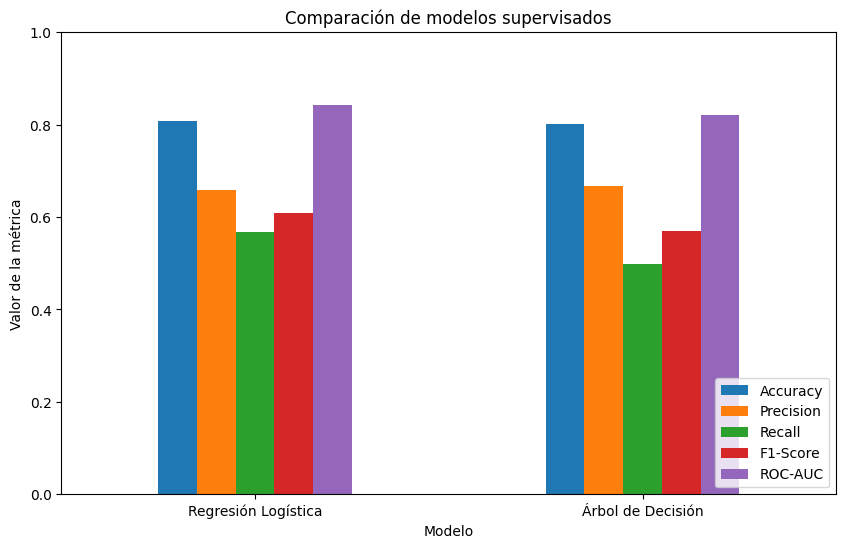

In [ ]:
comparacion_grafico = comparacion_modelos.set_index("Modelo")

comparacion_grafico.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparación de modelos supervisados")
plt.ylabel("Valor de la métrica")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

### Interpretación de la comparación

Los dos modelos presentan resultados competitivos, pero con diferencias relevantes.

La **Regresión Logística** obtiene mejores resultados en:

- Accuracy: **80,70%** frente a **80,06%**.
- Recall: **56,68%** frente a **49,73%**.
- F1-Score: **60,92%** frente a **56,97%**.
- ROC-AUC: **84,18%** frente a **82,19%**.

El Árbol de Decisión optimizado obtiene una Precision ligeramente superior:

- **66,67%** frente a **65,84%** de la Regresión Logística.

Para el objetivo de negocio, el Recall tiene especial importancia porque representa la capacidad de detectar a los clientes que realmente abandonan.

La Regresión Logística detectó correctamente **212 de 374 abandonos reales**, mientras que el Árbol de Decisión detectó **186**.

Por lo tanto, aunque el Árbol presenta una Precision levemente mayor, la **Regresión Logística ofrece el mejor equilibrio para este problema**, especialmente por su mayor Recall, F1-Score y ROC-AUC.

## 25. Selección del modelo supervisado

A partir de los resultados obtenidos, se selecciona la **Regresión Logística** como el modelo supervisado más adecuado entre las alternativas evaluadas.

La decisión no se basa únicamente en Accuracy. La Regresión Logística presenta un Recall de **56,68%**, superior al **49,73%** del Árbol de Decisión optimizado, además de un mejor F1-Score y ROC-AUC.

Para este problema es importante detectar la mayor cantidad posible de clientes que realmente abandonarán, ya que estos representan oportunidades para implementar acciones de retención.

Sin embargo, el Recall de 56,68% también muestra que la Regresión Logística deja sin detectar aproximadamente un **43,32% de los abandonos reales**.

Por esta razón, el modelo se recomienda como herramienta de apoyo y no como único mecanismo para tomar decisiones automáticas sobre clientes.

## 26. Preparación para aprendizaje no supervisado

Además de los modelos supervisados, se aplicará una técnica de aprendizaje no supervisado para identificar grupos de clientes con características similares.

Se utilizará K-Means, un algoritmo de clustering que agrupa observaciones según su similitud.

Para construir los clústeres se utilizarán variables numéricas relacionadas con la relación comercial del cliente:

- `tenure`
- `MonthlyCharges`
- `TotalCharges`

La variable `Churn` no se utilizará para formar los grupos, ya que en aprendizaje no supervisado no existe una variable objetivo.

## 27. Selección y escalamiento de variables para K-Means

K-Means agrupa clientes utilizando distancias entre observaciones.

Debido a que las variables seleccionadas poseen escalas diferentes, se aplica `StandardScaler` para colocarlas en una escala comparable antes de realizar el clustering.

In [ ]:
variables_cluster = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

X_cluster = df[variables_cluster].copy()

scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(
    X_cluster
)

print("Dimensiones para clustering:", X_cluster.shape)

X_cluster.describe().round(2)

Dimensiones para clustering: (7043, 3)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 28. Selección del número de clústeres

Para determinar una cantidad adecuada de clústeres se prueban distintos valores de `K`.

Se utilizarán dos criterios:

- **Inercia:** permite evaluar qué tan compactos son los clústeres.
- **Silhouette Score:** permite evaluar qué tan bien separados se encuentran los grupos.

La selección final de `K` se realizará considerando ambos resultados.

In [ ]:
inercias = []
silhouettes = []

valores_k = range(2, 11)

for k in valores_k:
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo_kmeans.fit_predict(
        X_cluster_scaled
    )

    inercias.append(
        modelo_kmeans.inertia_
    )

    silhouettes.append(
        silhouette_score(
            X_cluster_scaled,
            etiquetas
        )
    )

resultados_k = pd.DataFrame({
    "K": list(valores_k),
    "Inercia": inercias,
    "Silhouette": silhouettes
})

resultados_k.round(4)

,K,Inercia,Silhouette
0,2,9712.1120,0.4797
1,3,6186.1869,0.4515
2,4,4148.4825,0.4722
3,5,3111.4022,0.4437
4,6,2562.9284,0.4397
5,7,2204.4482,0.4501
6,8,1863.2142,0.4247
7,9,1624.1977,0.4337
8,10,1411.4530,0.4349


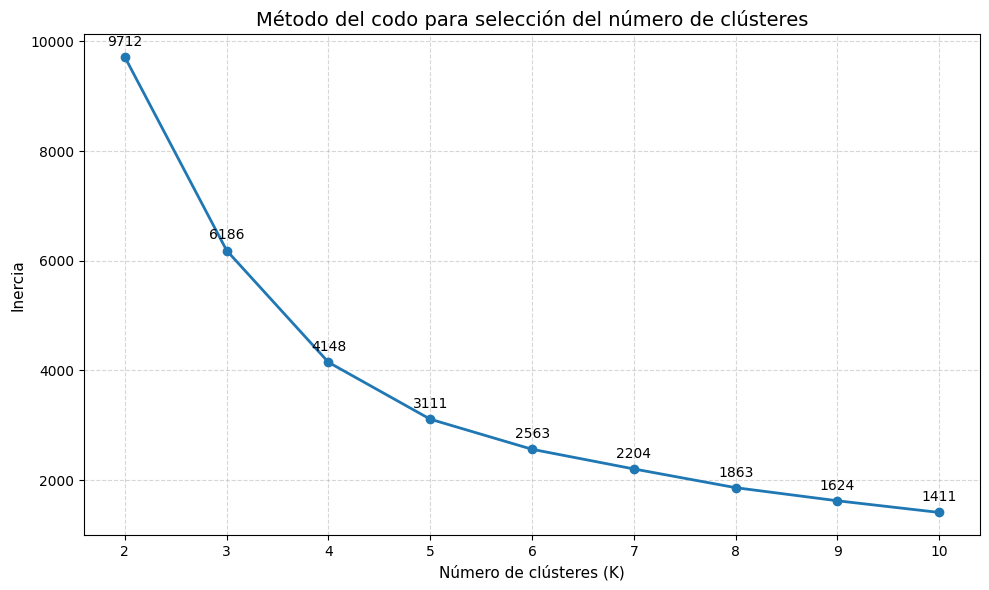

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    resultados_k["K"],
    resultados_k["Inercia"],
    marker="o",
    linewidth=2
)

# Mostrar el valor exacto de la inercia en cada punto
for k, inercia in zip(
    resultados_k["K"],
    resultados_k["Inercia"]
):
    plt.annotate(
        f"{inercia:.0f}",
        (k, inercia),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.title(
    "Método del codo para selección del número de clústeres",
    fontsize=14
)

plt.xlabel(
    "Número de clústeres (K)",
    fontsize=11
)

plt.ylabel(
    "Inercia",
    fontsize=11
)

plt.xticks(
    resultados_k["K"]
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()
plt.show()

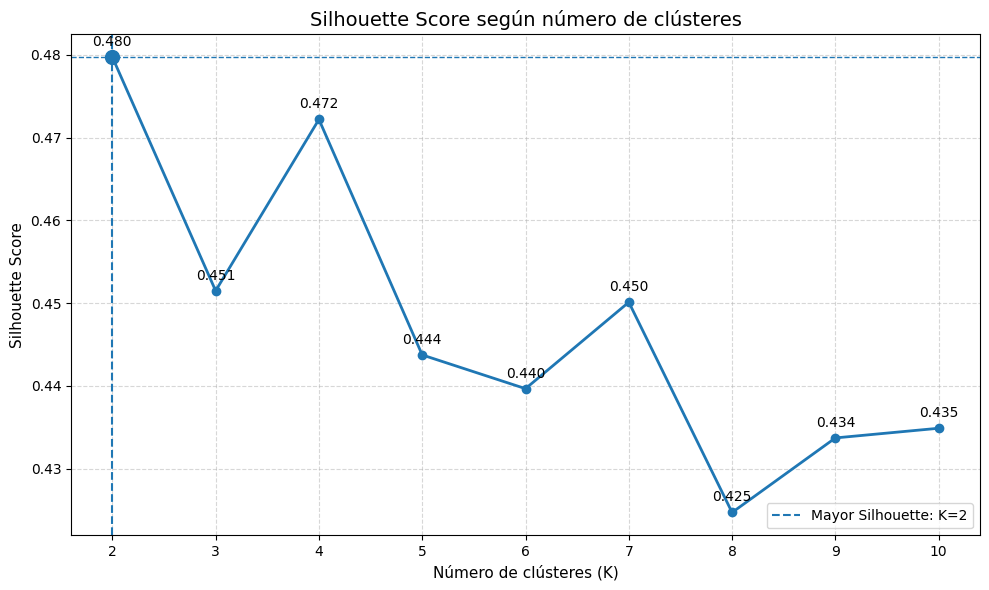

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    resultados_k["K"],
    resultados_k["Silhouette"],
    marker="o",
    linewidth=2
)

# Mostrar el valor exacto en cada punto
for k, silueta in zip(
    resultados_k["K"],
    resultados_k["Silhouette"]
):
    plt.annotate(
        f"{silueta:.3f}",
        (k, silueta),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

# Identificar automáticamente el K con mayor Silhouette
indice_mejor = resultados_k["Silhouette"].idxmax()

mejor_k_silhouette = resultados_k.loc[
    indice_mejor,
    "K"
]

mejor_silhouette = resultados_k.loc[
    indice_mejor,
    "Silhouette"
]

# Línea vertical en el mejor K
plt.axvline(
    x=mejor_k_silhouette,
    linestyle="--",
    linewidth=1.5,
    label=f"Mayor Silhouette: K={int(mejor_k_silhouette)}"
)

# Línea horizontal en el valor obtenido
plt.axhline(
    y=mejor_silhouette,
    linestyle="--",
    linewidth=1
)

# Destacar el punto
plt.scatter(
    mejor_k_silhouette,
    mejor_silhouette,
    s=100,
    zorder=5
)

plt.title(
    "Silhouette Score según número de clústeres",
    fontsize=14
)

plt.xlabel(
    "Número de clústeres (K)",
    fontsize=11
)

plt.ylabel(
    "Silhouette Score",
    fontsize=11
)

plt.xticks(
    resultados_k["K"]
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.legend()

plt.tight_layout()
plt.show()

## 29. Selección final del número de clústeres

A partir de los resultados obtenidos mediante el método del codo y el Silhouette Score, se selecciona **K = 4** para construir el modelo final de K-Means.

En el método del codo se observa una disminución importante de la inercia hasta aproximadamente cuatro clústeres. A partir de ese punto, las reducciones continúan, pero con una mejora progresivamente menor.

Por otra parte, el mayor Silhouette Score se obtiene con K = 2, con un valor aproximado de 0,480. Sin embargo, K = 4 obtiene un valor de aproximadamente 0,472, muy cercano al máximo.

Por lo tanto, se selecciona K = 4 porque mantiene una buena separación entre los grupos y permite obtener una segmentación más detallada de los clientes.

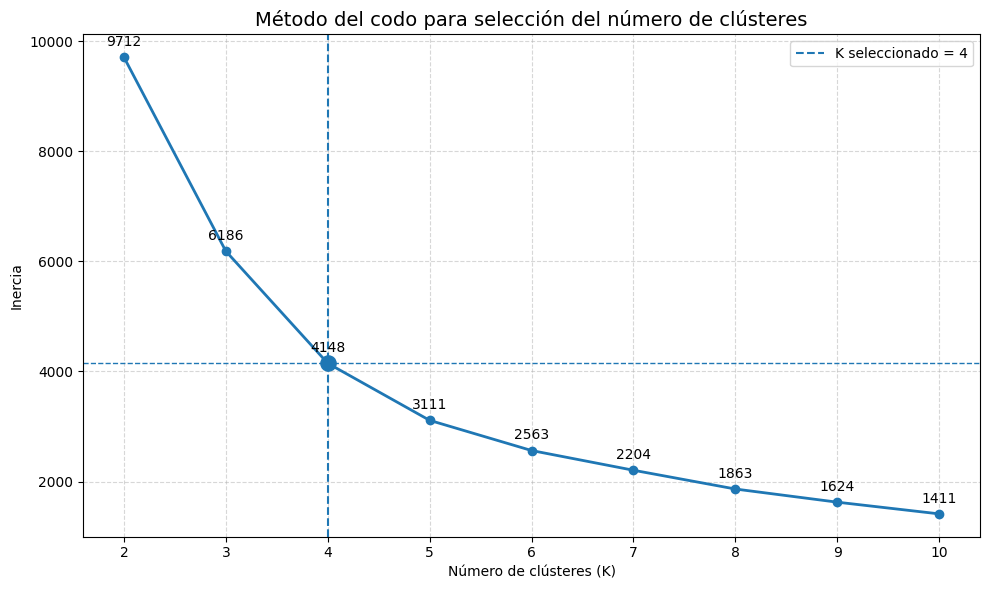

In [ ]:
k_seleccionado = 4

inercia_k4 = resultados_k.loc[
    resultados_k["K"] == k_seleccionado,
    "Inercia"
].iloc[0]

plt.figure(figsize=(10, 6))

plt.plot(
    resultados_k["K"],
    resultados_k["Inercia"],
    marker="o",
    linewidth=2
)

# Valores exactos
for k, inercia in zip(
    resultados_k["K"],
    resultados_k["Inercia"]
):
    plt.annotate(
        f"{inercia:.0f}",
        (k, inercia),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

# Línea vertical en K seleccionado
plt.axvline(
    x=k_seleccionado,
    linestyle="--",
    linewidth=1.5,
    label="K seleccionado = 4"
)

# Línea horizontal hasta la inercia correspondiente
plt.axhline(
    y=inercia_k4,
    linestyle="--",
    linewidth=1
)

# Punto destacado
plt.scatter(
    k_seleccionado,
    inercia_k4,
    s=120,
    zorder=5
)

plt.title(
    "Método del codo para selección del número de clústeres",
    fontsize=14
)

plt.xlabel("Número de clústeres (K)")
plt.ylabel("Inercia")

plt.xticks(resultados_k["K"])

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.legend()
plt.tight_layout()
plt.show()

## 30. Modelo final de K-Means

Una vez seleccionado K = 4, se construye el modelo definitivo de K-Means utilizando las variables previamente escaladas.

El objetivo es asignar cada cliente a uno de los cuatro clústeres según la similitud de sus características de antigüedad, cargos mensuales y cargos totales.

In [ ]:
modelo_kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = modelo_kmeans_final.fit_predict(
    X_cluster_scaled
)

df["Cluster"] = clusters

print("Modelo K-Means entrenado correctamente.")
print("\nCantidad de clientes por clúster:")
print(
    df["Cluster"]
    .value_counts()
    .sort_index()
)

Modelo K-Means entrenado correctamente.

Cantidad de clientes por clúster:
Cluster
0    1703
1    1904
2    2276
3    1160
Name: count, dtype: int64


## 31. Perfil de los clústeres

Una vez asignado cada cliente a un clúster, se calculan los valores promedio de las variables utilizadas en la segmentación.

Esto permite identificar las principales características de cada grupo y posteriormente interpretar su posible significado desde el punto de vista del negocio.

In [ ]:
perfil_clusters = (
    df.groupby("Cluster")[
        [
            "tenure",
            "MonthlyCharges",
            "TotalCharges"
        ]
    ]
    .mean()
    .round(2)
)

cantidad_clientes_cluster = (
    df["Cluster"]
    .value_counts()
    .sort_index()
    .rename("CantidadClientes")
)

perfil_completo = perfil_clusters.copy()

perfil_completo.insert(
    0,
    "CantidadClientes",
    cantidad_clientes_cluster
)

perfil_completo

,CantidadClientes,tenure,MonthlyCharges,TotalCharges
Cluster,,,,
0,1703,10.21,31.78,302.15
1,1904,59.53,93.31,5548.65
2,2276,15.42,80.78,1251.17
3,1160,53.57,34.91,1835.62


### Interpretación de los clústeres

Los cuatro clústeres presentan perfiles diferentes según la antigüedad del cliente, su cargo mensual y sus cargos totales acumulados.

- **Clúster 0 — Clientes recientes con bajo gasto mensual:**  
  presentan una antigüedad promedio de **10,21 meses**, cargos mensuales de aproximadamente **31,78** y cargos totales de **302,15**. Corresponde a clientes relativamente nuevos y con un nivel de gasto mensual bajo.

- **Clúster 1 — Clientes antiguos con alto gasto:**  
  presentan la mayor antigüedad promedio, con **59,53 meses**, junto con los cargos mensuales más elevados, de aproximadamente **93,31**, y los mayores cargos totales, con **5.548,65**. Este grupo representa clientes con una relación prolongada con la empresa y un nivel de gasto elevado.

- **Clúster 2 — Clientes recientes con alto gasto mensual:**  
  presentan una antigüedad promedio de **15,42 meses**, pero cargos mensuales elevados, cercanos a **80,78**. Sus cargos totales alcanzan aproximadamente **1.251,17**. Este grupo se diferencia por combinar poca antigüedad con un gasto mensual alto.

- **Clúster 3 — Clientes antiguos con bajo gasto mensual:**  
  presentan una antigüedad promedio de **53,57 meses**, cargos mensuales relativamente bajos, de aproximadamente **34,91**, y cargos totales de **1.835,62**. Corresponde a clientes con una relación prolongada con la empresa, pero con un nivel de gasto mensual menor.

La segmentación permite distinguir principalmente a los clientes según dos dimensiones: **antigüedad** y **nivel de gasto mensual**.

Esto puede ser útil para diseñar estrategias diferenciadas según el perfil de cada grupo, en lugar de aplicar las mismas acciones a todos los clientes.

In [ ]:
df["Cluster"].value_counts().sort_index()

Cluster
0    1703
1    1904
2    2276
3    1160
Name: count, dtype: int64

## 32. Análisis de abandono según clúster

Una vez construidos los clústeres, se analiza la distribución de `Churn` dentro de cada grupo.

La variable `Churn` no fue utilizada para formar los clústeres. Por lo tanto, este análisis se realiza posteriormente con el objetivo de evaluar si los segmentos identificados presentan diferencias en sus tasas de abandono.

In [ ]:
churn_por_cluster = pd.crosstab(
    df["Cluster"],
    df["Churn"],
    normalize="index"
) * 100

churn_por_cluster.round(2)

Churn,No,Yes
Cluster,,
0,75.34,24.66
1,84.61,15.39
2,51.76,48.24
3,95.00,5.00


In [ ]:
cantidad_churn_cluster = pd.crosstab(
    df["Cluster"],
    df["Churn"]
)

cantidad_churn_cluster

Churn,No,Yes
Cluster,,
0,1283,420
1,1611,293
2,1178,1098
3,1102,58


### Interpretación del abandono por clúster

Los cuatro segmentos presentan diferencias importantes en sus tasas de abandono.

- **Clúster 0 — Clientes recientes con bajo gasto:** presenta una tasa de abandono de **24,66%**, correspondiente a 420 de 1.703 clientes.
- **Clúster 1 — Clientes antiguos con alto gasto:** presenta una tasa de abandono de **15,39%**, correspondiente a 293 de 1.904 clientes.
- **Clúster 2 — Clientes recientes con alto gasto mensual:** presenta la mayor tasa de abandono, con **48,24%**, correspondiente a 1.098 de 2.276 clientes.
- **Clúster 3 — Clientes antiguos con bajo gasto mensual:** presenta la menor tasa de abandono, con solo **5,00%**, correspondiente a 58 de 1.160 clientes.

El resultado más relevante se observa en el **Clúster 2**, donde prácticamente uno de cada dos clientes abandona la empresa.

Este grupo combina una antigüedad relativamente baja, de aproximadamente 15,42 meses, con cargos mensuales elevados, cercanos a 80,78. Por lo tanto, representa un segmento especialmente relevante para futuras estrategias de retención.

En contraste, el Clúster 3 presenta una tasa de abandono considerablemente menor, lo que coincide con un perfil de clientes con mayor antigüedad y cargos mensuales bajos.

Es importante señalar que `Churn` no fue utilizado para construir los clústeres. La tasa de abandono fue analizada posteriormente para comprender el comportamiento de los segmentos encontrados por K-Means.

Las diferencias observadas corresponden a asociaciones dentro del conjunto de datos y no permiten establecer relaciones causales.

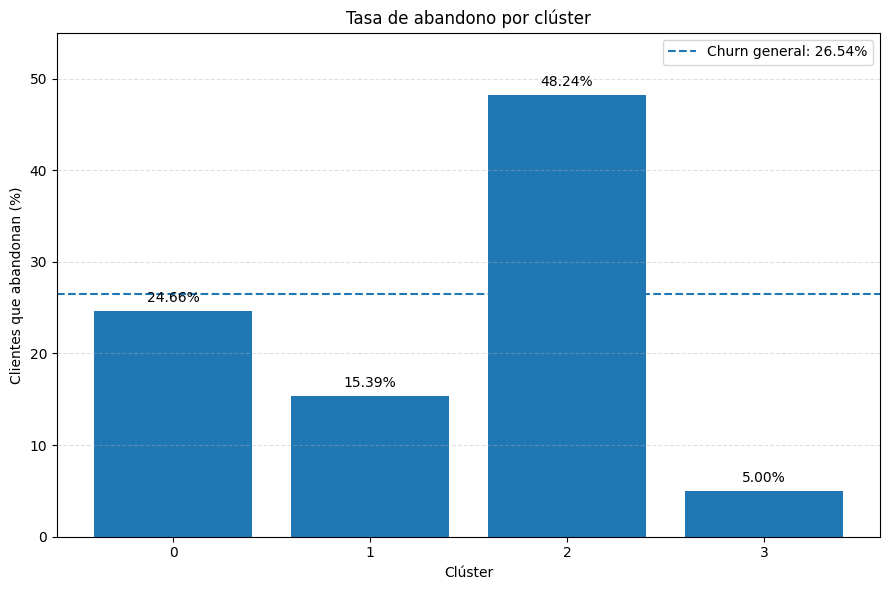

In [ ]:
tasa_churn_cluster = (
    df.groupby("Cluster")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

tasa_churn_general = (df["Churn"] == "Yes").mean() * 100

plt.figure(figsize=(9, 6))

barras = plt.bar(
    tasa_churn_cluster.index,
    tasa_churn_cluster.values
)

# Mostrar porcentaje exacto sobre cada barra
for barra, valor in zip(barras, tasa_churn_cluster.values):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{valor:.2f}%",
        ha="center"
    )

# Línea de referencia con churn general
plt.axhline(
    y=tasa_churn_general,
    linestyle="--",
    linewidth=1.5,
    label=f"Churn general: {tasa_churn_general:.2f}%"
)

plt.title("Tasa de abandono por clúster")
plt.xlabel("Clúster")
plt.ylabel("Clientes que abandonan (%)")
plt.xticks([0, 1, 2, 3])
plt.ylim(0, 55)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

## 33. Visualización de los clústeres mediante PCA

Para visualizar los grupos obtenidos mediante K-Means, se aplica Análisis de Componentes Principales (PCA).

PCA permite reducir las tres variables utilizadas en el clustering a dos componentes principales que pueden representarse en un gráfico bidimensional.

Es importante señalar que PCA no se utiliza para crear los clústeres. Los grupos ya fueron obtenidos previamente mediante K-Means utilizando `tenure`, `MonthlyCharges` y `TotalCharges`.

En esta etapa, PCA se utiliza únicamente como herramienta de visualización.

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    X_cluster_scaled
)

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

df_pca["Cluster"] = df["Cluster"].values

print("Varianza explicada por PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Varianza explicada por PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Varianza explicada acumulada:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Varianza explicada por PC1: 72.69 %
Varianza explicada por PC2: 25.33 %
Varianza explicada acumulada: 98.01 %


### Interpretación de la varianza explicada

El primer componente principal (`PC1`) explica aproximadamente el **72,69%** de la variabilidad presente en las variables utilizadas para el clustering.

El segundo componente (`PC2`) explica aproximadamente un **25,33%** adicional.

En conjunto, ambos componentes conservan aproximadamente el **98,01% de la varianza original**.

Esto significa que la representación en dos dimensiones conserva prácticamente toda la información contenida en las tres variables utilizadas (`tenure`, `MonthlyCharges` y `TotalCharges`).

Por lo tanto, el gráfico bidimensional obtenido mediante PCA permite representar de manera adecuada la estructura de los datos utilizada en el clustering.

Es importante señalar que PCA no creó los clústeres. Los grupos fueron generados previamente mediante K-Means y PCA se utiliza en esta etapa únicamente para facilitar su visualización.

## 34. Visualización de los clústeres en dos dimensiones

Utilizando los dos componentes principales obtenidos mediante PCA, se representan gráficamente los cuatro clústeres encontrados por K-Means.

Los ejes muestran el porcentaje de varianza explicado por cada componente, permitiendo conocer cuánta información de las variables originales está representada en cada dimensión.

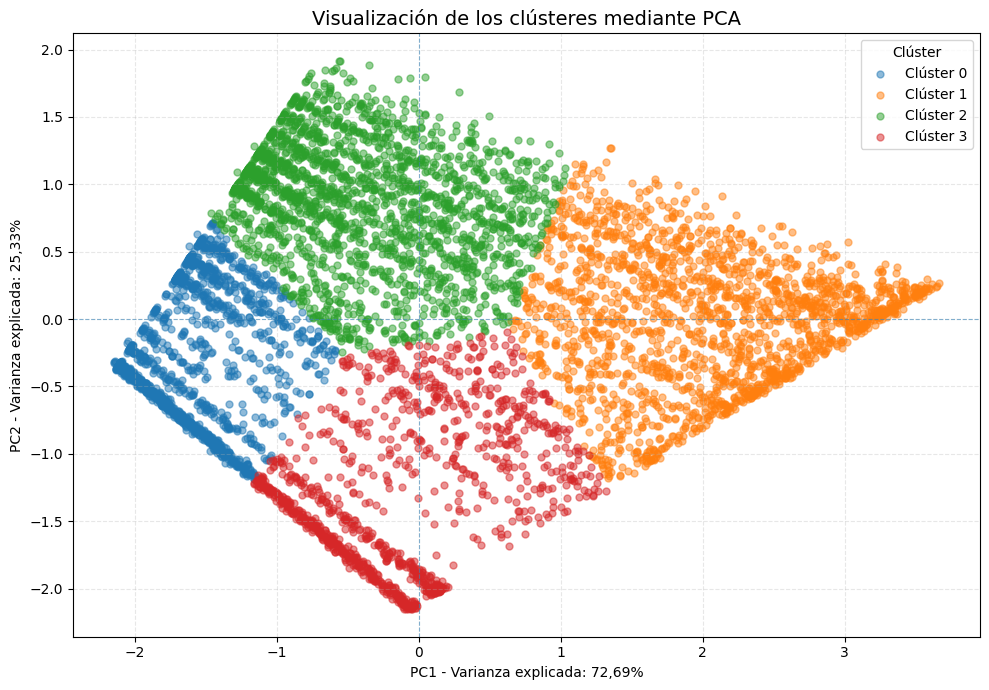

In [ ]:
plt.figure(figsize=(10, 7))

for cluster in sorted(df_pca["Cluster"].unique()):
    datos_cluster = df_pca[
        df_pca["Cluster"] == cluster
    ]

    plt.scatter(
        datos_cluster["PC1"],
        datos_cluster["PC2"],
        label=f"Clúster {cluster}",
        alpha=0.5,
        s=25
    )

plt.title(
    "Visualización de los clústeres mediante PCA",
    fontsize=14
)

plt.xlabel(
    "PC1 - Varianza explicada: 72,69%"
)

plt.ylabel(
    "PC2 - Varianza explicada: 25,33%"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.5
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.5
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend(
    title="Clúster"
)

plt.tight_layout()
plt.show()

### Interpretación de la visualización PCA

La representación mediante PCA muestra que los cuatro clústeres ocupan regiones diferenciadas en el espacio de dos dimensiones.

El Clúster 0 se concentra principalmente hacia el sector izquierdo del gráfico, el Clúster 1 hacia el sector derecho, el Clúster 2 en la zona superior y el Clúster 3 en la zona inferior.

Aunque existe cierto solapamiento entre algunos grupos en las zonas de frontera, los clústeres presentan una separación visual clara en gran parte del espacio representado.

Los dos componentes principales utilizados explican en conjunto aproximadamente el **98,01% de la varianza original**, por lo que esta visualización conserva prácticamente toda la información de las variables utilizadas en el clustering.

Esto respalda que la segmentación obtenida mediante K-Means representa grupos con características diferenciadas.

Es importante recordar que PCA se utilizó únicamente para visualizar los grupos y no para construirlos.

## 35. Conclusión del aprendizaje no supervisado

El modelo K-Means permitió identificar cuatro segmentos de clientes a partir de su antigüedad, cargo mensual y cargos totales acumulados.

Los segmentos obtenidos fueron:

- **Clúster 0:** 1.703 clientes recientes con bajo gasto mensual.
- **Clúster 1:** 1.904 clientes antiguos con alto gasto.
- **Clúster 2:** 2.276 clientes recientes con alto gasto mensual.
- **Clúster 3:** 1.160 clientes antiguos con bajo gasto mensual.

El análisis posterior de `Churn` mostró diferencias importantes entre los grupos.

El **Clúster 2** presentó la mayor tasa de abandono, con **48,24%**, correspondiente a 1.098 de 2.276 clientes. Este segmento combina una antigüedad relativamente baja, de aproximadamente 15,42 meses, con cargos mensuales elevados, cercanos a 80,78.

En contraste, el **Clúster 3** presentó la menor tasa de abandono, con solamente **5,00%**.

Desde el punto de vista del negocio, el Clúster 2 representa un segmento prioritario para profundizar estrategias de retención, debido a su elevada tasa de abandono.

La segmentación no demuestra que las características del clúster sean la causa del abandono. Su función es identificar grupos con comportamientos diferentes que puedan apoyar decisiones comerciales más específicas.

## 36. Conclusiones generales

El proyecto tuvo como objetivo analizar y predecir el abandono de clientes de una empresa de telecomunicaciones.

Durante el análisis exploratorio se identificaron características asociadas a mayores tasas de abandono, entre ellas contratos mes a mes, fibra óptica, `Electronic check`, ausencia de soporte técnico, ausencia de seguridad online, menor antigüedad y cargos mensuales más elevados.

En aprendizaje supervisado se compararon dos modelos:

### Regresión Logística

- Accuracy: **80,70%**
- Precision: **65,84%**
- Recall: **56,68%**
- F1-Score: **60,92%**
- ROC-AUC: **84,18%**

### Árbol de Decisión optimizado

- Accuracy: **80,06%**
- Precision: **66,67%**
- Recall: **49,73%**
- F1-Score: **56,97%**
- ROC-AUC: **82,19%**

La Regresión Logística fue seleccionada porque presenta un mejor Recall, F1-Score y ROC-AUC, métricas especialmente relevantes para el objetivo de detectar clientes que realmente abandonan.

Sin embargo, el modelo todavía deja sin detectar aproximadamente el **43,32% de los abandonos reales**, por lo que debe utilizarse como una herramienta de apoyo y no como único criterio de decisión.

En aprendizaje no supervisado, K-Means permitió identificar cuatro segmentos. El **Clúster 2**, compuesto por clientes relativamente recientes y con cargos mensuales altos, presentó la mayor tasa de abandono, con **48,24%**.

En conjunto, los resultados permiten abordar el problema desde dos niveles:

- identificar clientes individuales con señales de riesgo mediante clasificación;
- identificar segmentos con comportamientos diferenciados mediante clustering.

Esto puede apoyar estrategias de retención más focalizadas.

## 37. Consideraciones éticas

Los resultados del proyecto deben utilizarse de manera responsable.

- Una predicción de abandono representa una estimación del modelo y no una certeza.
- Las asociaciones encontradas en el EDA no demuestran causalidad.
- Pertenecer a un clúster no implica que todos los integrantes del grupo tengan exactamente el mismo comportamiento.
- Las decisiones sobre clientes no deberían basarse exclusivamente en características personales.
- Los resultados deben utilizarse como apoyo a la toma de decisiones y complementarse con criterios de negocio y revisión humana.


## 38. Aplicación de la metodología CRISP-DM

El proyecto se desarrolló siguiendo las etapas principales de la metodología CRISP-DM.

### 1. Comprensión del negocio

Se definió como problema principal la necesidad de identificar clientes con riesgo de abandonar la empresa, con el objetivo de apoyar futuras estrategias de retención.

### 2. Comprensión de los datos

Se analizaron las dimensiones del conjunto de datos, tipos de variables, distribución de `Churn`, registros duplicados, valores faltantes y principales características de los clientes.

También se realizó un análisis exploratorio para identificar patrones asociados al abandono.

### 3. Preparación de los datos

Se corrigió la variable `TotalCharges`, se trataron sus registros vacíos, se eliminó `customerID` del modelamiento y se transformaron las variables categóricas a formato numérico.

Posteriormente, los datos fueron divididos en conjuntos de entrenamiento y prueba y se realizó escalamiento cuando fue necesario.

### 4. Modelamiento

Se implementaron y compararon dos modelos supervisados:

- Regresión Logística.
- Árbol de Decisión, con optimización de `max_depth` mediante GridSearchCV.

Además, se utilizó K-Means como técnica de aprendizaje no supervisado para identificar segmentos de clientes.

### 5. Evaluación

Los modelos supervisados fueron evaluados mediante Accuracy, Precision, Recall, F1-Score, ROC-AUC y matrices de confusión.

Para K-Means se utilizaron el método del codo y Silhouette Score para seleccionar el número de clústeres.

También se utilizó PCA para visualizar los segmentos encontrados.

### 6. Aplicación al contexto de negocio

Los resultados fueron interpretados considerando el objetivo de reducir el abandono de clientes.

La Regresión Logística presentó el mejor desempeño entre los modelos supervisados evaluados, mientras que el clustering permitió identificar un segmento con una tasa de abandono particularmente elevada.

Los resultados deben ser utilizados como apoyo a la toma de decisiones y no como decisiones automáticas sobre los clientes.